# psfcal on real HARPS data: PSF of a laser-frequency-comb chunk

The synthetic notebooks (`quickstart`, `parameters`) are handy because the true PSF is known.
Here we do the real thing: reconstruct the instrumental profile of **HARPS** from a **laser frequency comb (LFC)** exposure.

LFC lines are unresolved, equally spaced and almost identical, so every line is a direct image of the PSF.
psfcal stacks all the lines of a chunk, which samples the profile on a fine sub-pixel grid.

Contents: 1. the data · 2. fit · 3. the PSF · 4. why stacking works · 5. why the background matters · 6. using the PSF (deconvolution)

**Data.** `data/harps_lfc_order60_chunk.npz` is a 276-pixel slice (chunk 8 of 16 of order 60, plus 10 px margin on each side) of the public ESO-archive HARPS LFC exposure `r.HARPS.2015-04-23T17:45:57.267_S2D_LFC_LFC_A` (flux and error arrays of the S2D product).
The fits are cached in `data/harps_lfc_fit_cache.pkl`; set `RECOMPUTE = True` to redo them (~1 min each).

In [1]:
import pickle, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

import psfcal
from psfcal import plotting

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

RECOMPUTE = False
DATA = Path("data")
CACHE = DATA / "harps_lfc_fit_cache.pkl"
PIX_MS = 820.0                      # 1 HARPS pixel ~ 820 m/s (approximate, for converting widths)

d = np.load(DATA / "harps_lfc_order60_chunk.npz")
x, flux, err = d["x"], d["flux"], d["err"]
print(str(d["info"]))
print(f"{len(x)} pixels, flux {flux.min():.0f}-{flux.max():.0f} counts")

HARPS laser frequency comb exposure r.HARPS.2015-04-23T17:45:57.267_S2D_LFC_LFC_A (ESO archive), order 60 (1-based), detector pixels 2038-2314 (chunk 8 of 16 + 10 px margin)
276 pixels, flux 3254-124029 counts


## 1. The data

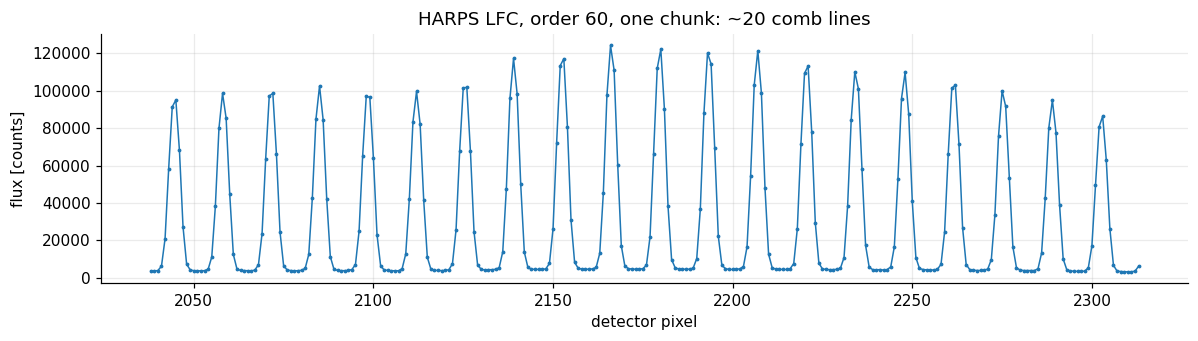

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(x, flux, lw=1, marker=".", ms=3)
ax.set(xlabel="detector pixel", ylabel="flux [counts]", title="HARPS LFC, order 60, one chunk: ~20 comb lines")
plt.tight_layout(); plt.show()

About 20 comb lines, ~13.7 pixels apart, each only ~4 pixels wide: a single line samples its profile at just a few points.
Note the **background** of a few thousand counts between the lines (scattered light plus the overlapping wings of the neighbours): it is not zero, which matters below.

## 2. Fit

In [3]:
if CACHE.exists() and not RECOMPUTE:
    fits_ = pickle.load(open(CACHE, "rb"))
else:
    fits_ = {}
    for key, kw in [("bkg_on", dict(subtract_background=True)), ("bkg_off", dict(subtract_background=False))]:
        t0 = time.time()
        r = psfcal.compute_psf_chunk_pixel(x, flux, err, **kw)
        fits_[key] = {q: r[q] for q in ("psf_x", "psf_mean", "psf_std", "stacked_x", "stacked_y", "stacked_yerr",
                                          "rms", "line_centres", "background")}
        fits_[key]["psf_area_norm"] = r.get("psf_area_norm", 1.0)
        print(key, f"{time.time() - t0:.0f}s")
    pickle.dump(fits_, open(CACHE, "wb"))

good = fits_["bkg_on"]
print(f"{len(good['line_centres'])} lines stacked into {len(good['stacked_x'])} points; "
      f"residual RMS = {good['rms']:.1f} sigma")

20 lines stacked into 291 points; residual RMS = 2.9 sigma


The call is just

```python
r = psfcal.compute_psf_chunk_pixel(x, flux, err, subtract_background=True)
```

`subtract_background=True` is needed here because the raw flux sits on a background (section 5).
`r["psf_x"], r["psf_mean"]` is the PSF; `r["psf_std"]` its uncertainty.

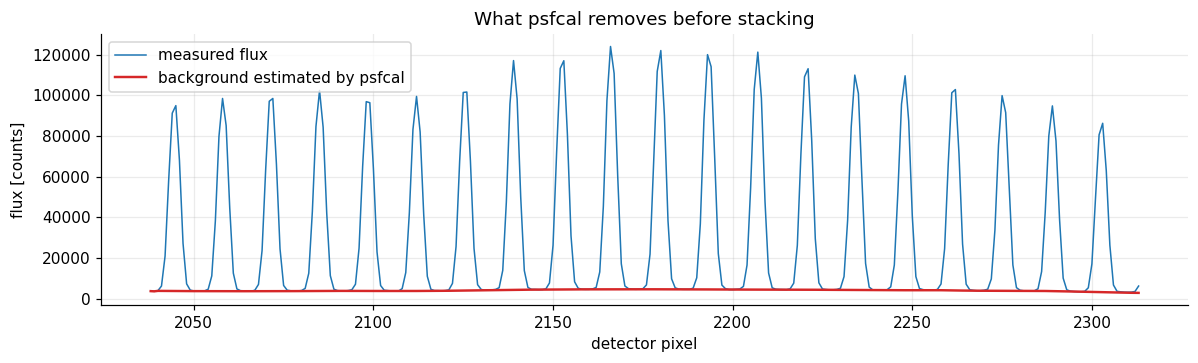

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(x, flux, lw=1, label="measured flux")
ax.plot(x, good["background"], c="tab:red", lw=1.6, label="background estimated by psfcal")
ax.set(xlabel="detector pixel", ylabel="flux [counts]", title="What psfcal removes before stacking")
ax.legend(); plt.tight_layout(); plt.show()

## 3. The reconstructed PSF

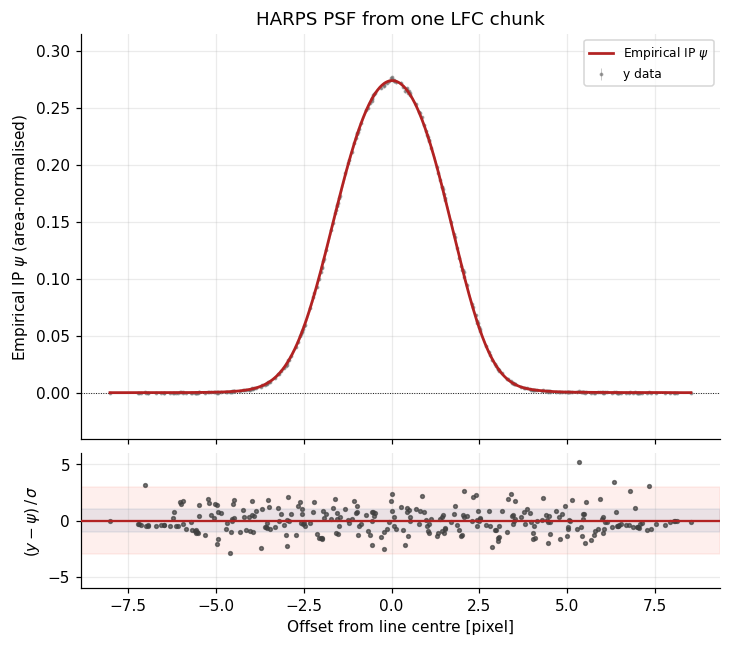

FWHM ~ 3.54 px  (~2903 m/s)   centroid = +0.000 px (set to 0 by construction)


In [5]:
fig, (a1, a2) = plotting.plot_psf(good, title="HARPS PSF from one LFC chunk", xlabel="Offset from line centre [pixel]")
plt.show()

px, py = good["psf_x"], good["psf_mean"]
half = py.max() / 2
inside = px[py >= half]
fwhm = inside.max() - inside.min()
cen = np.trapz(px * py, px) / np.trapz(py, px)
print(f"FWHM ~ {fwhm:.2f} px  (~{fwhm * PIX_MS:.0f} m/s)   centroid = {cen:+.3f} px (set to 0 by construction)")

Top: every grey point is one pixel of one line, placed at its offset from that line's centre; the red curve is the Gaussian-process fit and its band the 1σ uncertainty.
Bottom: residuals in units of the photon-noise error, with the ±1σ and ±3σ bands shaded.
In this chunk the profile is close to a Gaussian of FWHM ≈ 3.5 px; in other orders, positions on the detector and epochs it deviates more (asymmetry, wings), which is what a single-Gaussian line model cannot capture. psfcal measures whatever shape is there.

## 4. Why stacking works: sub-pixel sampling

The detector samples each line only at integer pixel positions, but the lines fall at different sub-pixel positions relative to the pixel grid.
If the fractional positions cover the range 0–1 evenly, the stack fills in the whole profile.

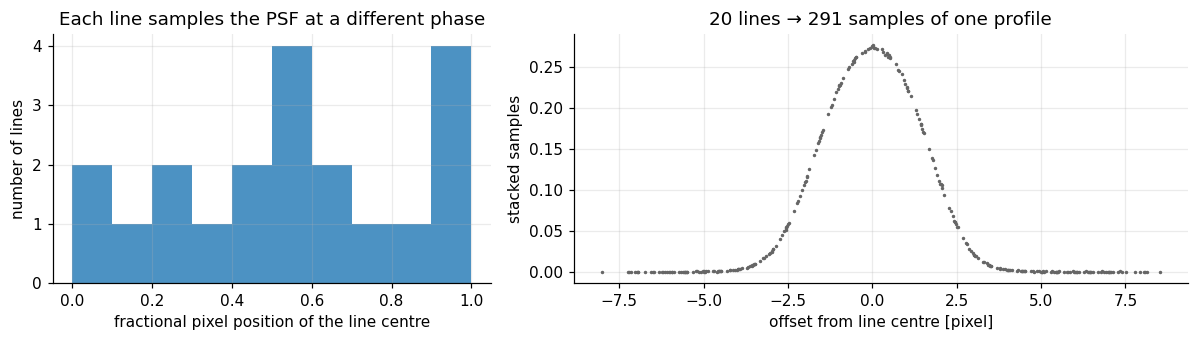

In [6]:
frac = np.mod(good["line_centres"], 1.0)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[1, 1.4]))
a.hist(frac, bins=np.linspace(0, 1, 11), color="tab:blue", alpha=0.8)
a.set(xlabel="fractional pixel position of the line centre", ylabel="number of lines",
      title="Each line samples the PSF at a different phase")
sx = good["stacked_x"]
b.plot(sx, good["stacked_y"] / good["psf_area_norm"], ".", ms=2.5, c="0.4")
b.set(xlabel="offset from line centre [pixel]", ylabel="stacked samples",
      title=f"{len(good['line_centres'])} lines → {len(sx)} samples of one profile")
plt.tight_layout(); plt.show()

## 5. Why the background matters (on real data)

Same chunk, same code, only `subtract_background` changes.

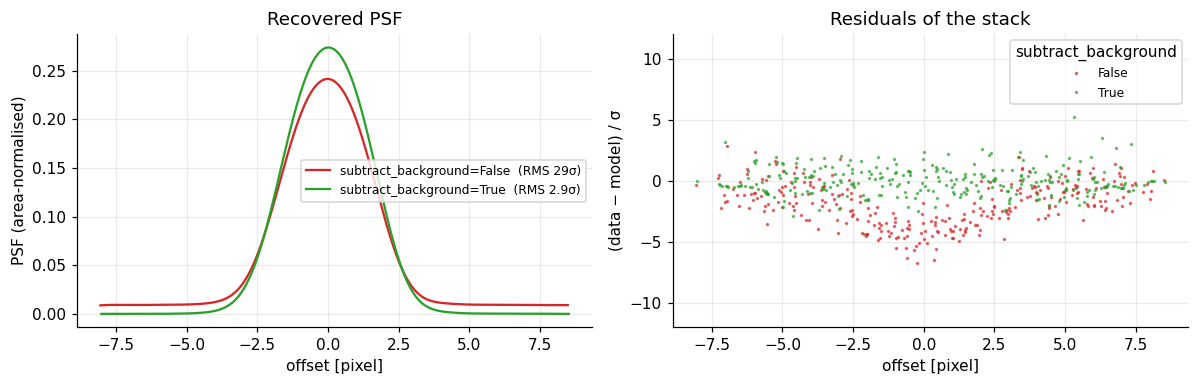

In [7]:
off = fits_["bkg_off"]
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
a.plot(off["psf_x"], off["psf_mean"], c="tab:red", label=f"subtract_background=False  (RMS {off['rms']:.0f}σ)")
a.plot(good["psf_x"], good["psf_mean"], c="tab:green", label=f"subtract_background=True  (RMS {good['rms']:.1f}σ)")
a.set(xlabel="offset [pixel]", ylabel="PSF (area-normalised)", title="Recovered PSF"); a.legend(fontsize=8)
for r_, col, lab in [(off, "tab:red", "False"), (good, "tab:green", "True")]:
    sy = r_["stacked_y"] / r_["psf_area_norm"]
    b.plot(r_["stacked_x"], (sy - np.interp(r_["stacked_x"], r_["psf_x"], r_["psf_mean"])) / (r_["stacked_yerr"] / r_["psf_area_norm"]),
           ".", ms=2.5, c=col, alpha=0.6, label=lab)
b.set(xlabel="offset [pixel]", ylabel="(data − model) / σ", ylim=(-12, 12), title="Residuals of the stack"); b.legend(title="subtract_background", fontsize=8)
plt.tight_layout(); plt.show()

Without background subtraction the lines are normalised to the wrong area and the wings are lifted: the PSF is biased and the fit is poor (residual RMS ~10× larger).
**For real spectra use `subtract_background=True`** (the cube helper `compute_psf_cube_pixel` already does by default).

## 6. Using the PSF: deconvolve the chunk

Deconvolving the LFC chunk with its own PSF should return the comb to (nearly) unresolved spikes.
This also checks that the PSF is self-consistent. We subtract the estimated background first.

median line FWHM: observed 3.61 px  →  deconvolved 1.14 px   (20 lines)


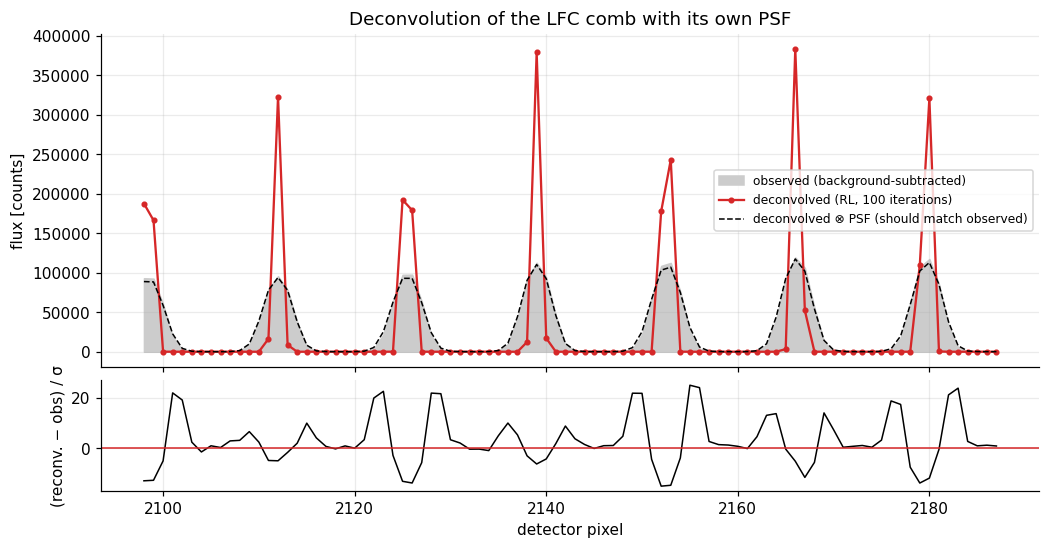

In [8]:
spec = flux - good["background"]
scale = spec.max()                      # work with flux of order 1 (see the note below)
deconv = scale * psfcal.deconvolve_chunk_pixel(spec / scale, good["psf_x"], good["psf_mean"], pixel_radius=7,
                                               rl_iters=100, overlap_pix=10, continuum_normalize=False)
back = psfcal.convolve_chunk_pixel(deconv, good["psf_x"], good["psf_mean"], pixel_radius=7)

def fwhm_of(y, x):
    # median FWHM [pixel] of the isolated peaks of y (linear interpolation at half maximum)
    pk, _ = find_peaks(y, height=0.5 * y.max(), distance=8)
    out = []
    for p in pk:
        if p < 6 or p > len(y) - 7: continue
        h = y[p] / 2
        l = p
        while l > 0 and y[l] > h: l -= 1
        r = p
        while r < len(y) - 1 and y[r] > h: r += 1
        xl = x[l] + (h - y[l]) / (y[l + 1] - y[l]) * (x[l + 1] - x[l])
        xr = x[r - 1] + (h - y[r - 1]) / (y[r] - y[r - 1]) * (x[r] - x[r - 1])
        out.append(xr - xl)
    return np.median(out), len(out)

f_obs, n1 = fwhm_of(spec, x)
f_dec, n2 = fwhm_of(deconv, x)
print(f"median line FWHM: observed {f_obs:.2f} px  →  deconvolved {f_dec:.2f} px   ({n1} lines)")

sl = slice(60, 150)
fig, (a, b) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw=dict(height_ratios=[3, 1], hspace=0.06))
a.fill_between(x[sl], spec[sl], color="0.8", label="observed (background-subtracted)")
a.plot(x[sl], deconv[sl], c="tab:red", lw=1.5, marker="o", ms=3, label="deconvolved (RL, 100 iterations)")
a.plot(x[sl], back[sl], "k--", lw=1, label="deconvolved ⊗ PSF (should match observed)")
a.set(ylabel="flux [counts]", title="Deconvolution of the LFC comb with its own PSF"); a.legend(fontsize=8)
b.plot(x[sl], (back - spec)[sl] / err[sl], c="k", lw=1)
b.axhline(0, c="tab:red", lw=1); b.set(xlabel="detector pixel", ylabel="(reconv. − obs) / σ")
plt.show()

The lines shrink from ≈3.6 px to ≈1.1 px FWHM, i.e. to about one pixel, which is all that pixel-sampled data can show for an unresolved comb line.
The re-convolved spectrum (dashed) follows the observation (bottom panel), to within a few percent of the line height.
`rl_iters` controls how far the sharpening goes (see `parameters.ipynb`, section 7).

> **Flux scale matters.** `l2_damp` acts on the flux in its own units. With raw counts of ~10⁵ the default `l2_damp=3e-6` dominates and Richardson–Lucy *stalls* (here at FWHM ≈ 3.1 px from 10 iterations onwards, with the re-convolved peaks only 61% of the observed). That is why we divide by the maximum first. If you keep the default `continuum_normalize=True`, psfcal rescales for you; when you set it to `False`, scale the flux yourself.

## Next steps

* **A whole order or detector:** `psfcal.compute_psf_cube_pixel(flux, err, orders_1based=..., n_chunks=16)` repeats this for every chunk; `psfcal.deconvolve_order` applies the result to a stellar spectrum. In our HARPS tests ~256-pixel chunks (16 per order) gave the best compromise between line count and PSF variation.
* **Other spectrographs (e.g. ESPRESSO):** nothing here is HARPS-specific; pass the flux and error of any calibration-lamp or LFC exposure with resolved, well-separated lines. If your calibrator lines are not unresolved (e.g. Fabry–Pérot), their intrinsic width is folded into the recovered profile.
* **Velocity-space PSF:** `compute_psf_chunk_rv` / `compute_psf_cube_rv` additionally take the wavelength solution and the theoretical comb wavelengths (see `quickstart.ipynb`).